# Assignment 07 — Hussein Jawad
**E89 Deep Learning · NLP with Transformers** (based on Géron, *Hands-On ML*, Ch. 15)

---

# Problem 1 — `prince - man + woman` with spaCy

Find the 5 vectors closest (cosine similarity) to `prince - man + woman`, identify the top one, and show the first 10 values of each vector.

## Approach

1. **Load word vectors:** load spaCy's large English model `en_core_web_lg`, which stores a 300-dimensional semantic vector for each word.
   - A **semantic vector** (word embedding) is a list of numbers that represents a word's *meaning* (hence "semantic"). The values are learned by training on huge amounts of text: each word starts with a random vector, and the vectors are adjusted so that a word can be predicted from its neighbors. As a result, words used in similar contexts get similar vectors (e.g., *prince* is close to *princess*, far from *banana*).
2. **Vector arithmetic:** look up the vectors for `prince`, `man`, and `woman`, and compute
   `query = prince − man + woman`
   (subtracting `man` and adding `woman` shifts the meaning from male to female while keeping "royalty").
3. **Cosine similarity search:** use spaCy's `nlp.vocab.vectors.most_similar(query, n=5)` to compare `query` with every word vector in `en_core_web_lg` (about 343,000 vectors) and return the 5 with the highest cosine similarity:

   $$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\| \, \|\mathbf{b}\|}$$

   (ranges from −1, opposite, to +1, same direction).
4. **Display:** convert each result back to its word, then print the word, its cosine similarity, and the first 10 values of its vector. The first result is the top match.

In [ ]:
!python -m spacy download en_core_web_lg   # download spaCy's large English model (it has word vectors)

import spacy         # spaCy NLP library
import numpy as np   # numerical arrays

np.set_printoptions(precision=4, linewidth=150)   # print each 10-value vector on one line, 4 decimals

nlp = spacy.load("en_core_web_lg")   # load the model (300-dimensional word vectors)

# Semantic vectors for the three words
prince = nlp.vocab["prince"].vector
man = nlp.vocab["man"].vector
woman = nlp.vocab["woman"].vector

query = prince - man + woman   # vector arithmetic: prince - man + woman

keys, rows, scores = nlp.vocab.vectors.most_similar(np.array([query]), n=5)   # 5 closest vectors by cosine similarity

# Show the 5 closest vectors: word, cosine similarity, first 10 values
for key, score in zip(keys[0], scores[0]):
    word = nlp.vocab.strings[key].lower()   # convert the vector key back to a word
    print(f"{word:<10} cosine = {score:.4f}   first 10 values: {nlp.vocab.vectors[key][:10]}")

print("Top match:", nlp.vocab.strings[keys[0][0]].lower())   # the single closest vector

# Problem 2 — French-to-English Transformer

| Step | Cell |
|---|---|
| 1 | Setup |
| 2 | Data |
| 3 | Tokenizer |
| 4 | Data loaders |
| 5 | Model |
| 6 | Training functions |
| 7 | Train and save |
| 8 | Compare (8a: pick 5 test sentences · 8b: compare with Google Translate) |

## Approach

- **Data:** OPUS-100 English–French sentence pairs (`Helsinki-NLP/opus-100`, config `en-fr`): short, everyday sentences. Géron's dataset (`ageron/tatoeba_mt_train`) only has English–Spanish (`eng-spa`). A first run with Opus Books (sentences from classic novels) translated poorly; see **Results**.
- **Reduced volume:** only pairs with up to 15 words on both sides, then a random subset of 200,000 pairs (`num_pairs`) to keep training time reasonable.
- **Split:** 10% of the pairs → **test set**; of the remaining 90%, 10% → validation set, the rest → training set (162,000 / 18,000 / 20,000 pairs).
- **Tokenizer:** one BPE tokenizer with a 10,000-token vocabulary shared by French and English (Géron's code), plus a decoder that turns token IDs back into readable text.
- **Model:** Géron's `NmtTransformer` (PyTorch `nn.Transformer` encoder–decoder), made bigger than his small settings: 256-dimensional embeddings, 8 attention heads, 3 encoder and 3 decoder layers (Géron: 128, 4, 2).
- **Training:** NAdam optimizer (learning rate 0.001), cross-entropy loss that ignores padding, batch size 64, 20 epochs, learning rate halved when validation accuracy stops improving. Accuracy ignores `<pad>` positions. (Run 2 used Géron's small model with a small batch size of 32; see **Results**.)
- **Saved model:** weights in `fr_en_transformer.pt`, tokenizer in `fr_en_tokenizer.json`.
- **Comparison:** 5 random test sentences with up to 10 words, translated with Google Translate (at translate.google.com, because calling it from Colab failed with "429 Too Many Requests") and with our Transformer (Géron's `translate()`, one token at a time). The last column lists the words that appear in only one of the two translations.

### Step 1 (Problem 2) — Setup

- Installs `torchmetrics` (not preinstalled on Colab), imports everything Problem 2 needs, and selects the GPU (Runtime → Change runtime type → GPU).

In [ ]:
%pip install -q torchmetrics   # not preinstalled on Colab: accuracy metric

import re                                       # regular expressions (to compare translations word by word)
import pandas as pd                             # table of results
import torch                                    # PyTorch
import torch.nn as nn                           # neural-network layers
import torchmetrics                             # accuracy metric used during training
import tokenizers                               # Hugging Face tokenizers (BPE)
from collections import namedtuple              # container for one batch of model inputs
from datasets import load_dataset               # Hugging Face datasets
from torch.utils.data import DataLoader         # splits a dataset into batches

device = "cuda" if torch.cuda.is_available() else "cpu"   # use Colab's GPU (Runtime > Change runtime type > GPU)
torch.manual_seed(42)                                     # reproducible results
print(device)                                             # should print "cuda"

### Step 2 (Problem 2) — Data

- Loads English–French sentence pairs from **OPUS-100** (short, everyday sentences), since Géron's Tatoeba copy has no French.
- Keeps only pairs with up to 15 words on both sides, then a random 200,000 of them to save training time.
- French is the source (goes into **Inputs [1]**) and English the target (**Outputs [8]**), so Géron's code works unchanged.
- 10% of the pairs are held out as the **test set** (never seen in training); 10% of the rest is the validation set.

In [ ]:
num_pairs = 200_000   # reduced data volume to keep training time reasonable on Colab
max_words = 15        # keep short sentences only (the test sentences have up to 10 words)

# English–French sentence pairs from OPUS-100 (short, everyday sentences)
pairs = load_dataset("Helsinki-NLP/opus-100", "en-fr", split="train")
# Same columns as Géron's code: French is the source, English is the target
pairs = pairs.map(lambda p: {"source_text": p["translation"]["fr"], "target_text": p["translation"]["en"]})
pairs = pairs.filter(lambda p: 0 < len(p["source_text"].split()) <= max_words
                     and 0 < len(p["target_text"].split()) <= max_words)    # short pairs only
pairs = pairs.shuffle(seed=42).select(range(min(num_pairs, len(pairs))))   # random subset of the pairs

split = pairs.train_test_split(test_size=0.1, seed=42)              # 10% of the French–English pairs → test set
nmt_test_set = split["test"]
split = split["train"].train_test_split(test_size=0.1, seed=42)     # 10% of the rest → validation set
nmt_train_set, nmt_valid_set = split["train"], split["test"]

print(len(nmt_train_set), len(nmt_valid_set), len(nmt_test_set))   # train / validation / test sizes

### Step 3 (Problem 2) — Tokenizer

*Part 0: "From words to numbers: tokenizer & vocabulary"*

- Learns **one shared BPE vocabulary** of 10,000 tokens from the French **and** English training sentences.
- BPE keeps frequent words whole and splits rare words into smaller pieces, so (almost) no word is unknown.
- These token IDs are the model's **Inputs [1]** and **Outputs [8]**; `vocab_size` sets the size of the embedding table **[2]/[9]** and the **Linear [12]** layer.
- Word pieces are marked with `##` (e.g. `average` + `##s`), so the decoder can join them back into readable text ("averages", not "average s").

In [ ]:
def train_fr_en():   # generator over all training text
    for pair in nmt_train_set:
        yield pair["source_text"]   # French sentence
        yield pair["target_text"]   # English sentence

max_length = 500      # longest token sequence allowed
vocab_size = 10_000   # size of the shared French + English vocabulary
nmt_tokenizer = tokenizers.Tokenizer(tokenizers.models.BPE(unk_token="<unk>", continuing_subword_prefix="##"))   # BPE; "##" marks word pieces
nmt_tokenizer.enable_padding(pad_id=0, pad_token="<pad>")                        # pad short sentences with <pad> (ID 0)
nmt_tokenizer.enable_truncation(max_length=max_length)                           # cut overly long sentences
nmt_tokenizer.pre_tokenizer = tokenizers.pre_tokenizers.Whitespace()             # split on spaces and punctuation first
nmt_tokenizer.decoder = tokenizers.decoders.WordPiece(prefix="##")               # token IDs → readable text (joins "##" pieces)
nmt_tokenizer_trainer = tokenizers.trainers.BpeTrainer(
    vocab_size=vocab_size, special_tokens=["<pad>", "<unk>", "<s>", "</s>"],     # special tokens get IDs 0–3
    continuing_subword_prefix="##")                                               # same "##" marker as the model
nmt_tokenizer.train_from_iterator(train_fr_en(), nmt_tokenizer_trainer)          # learn the vocabulary

### Step 4 (Problem 2) — Data loaders

- Géron's `nmt_collate_fn` turns each batch of sentence pairs into token-ID tensors and padding masks.
- English targets get `<s> … </s>`; the decoder input is the target **shifted right [8]**, and the labels are the next tokens.
- Padding masks mark `<pad>` tokens so attention ignores them (*Part 0b: "The two masks"*).
- Batch size 64 (Géron's), to keep training time reasonable with the bigger model. Run 2 used a small batch size of 32.

In [ ]:
fields = ["src_token_ids", "src_mask", "tgt_token_ids", "tgt_mask"]   # what the model receives
class NmtPair(namedtuple("NmtPairBase", fields)):                     # one batch of model inputs
    def to(self, device):                                             # move all four tensors to the GPU
        return NmtPair(self.src_token_ids.to(device), self.src_mask.to(device),
                       self.tgt_token_ids.to(device), self.tgt_mask.to(device))

def nmt_collate_fn(batch):   # turns a list of pairs into tensors
    src_texts = [pair["source_text"] for pair in batch]                 # French inputs
    tgt_texts = [f"<s> {pair['target_text']} </s>" for pair in batch]   # English targets with start/end tokens
    src_encodings = nmt_tokenizer.encode_batch(src_texts)               # tokenize French
    tgt_encodings = nmt_tokenizer.encode_batch(tgt_texts)               # tokenize English
    src_token_ids = torch.tensor([enc.ids for enc in src_encodings])    # French token IDs: Inputs [1]
    tgt_token_ids = torch.tensor([enc.ids for enc in tgt_encodings])    # English token IDs
    src_mask = torch.tensor([enc.attention_mask for enc in src_encodings])   # 1 = real token, 0 = padding
    tgt_mask = torch.tensor([enc.attention_mask for enc in tgt_encodings])   # 1 = real token, 0 = padding
    inputs = NmtPair(src_token_ids, src_mask,
                     tgt_token_ids[:, :-1], tgt_mask[:, :-1])           # decoder input: Outputs (shifted right) [8]
    labels = tgt_token_ids[:, 1:]                                       # labels: the next English token
    return inputs, labels

batch_size = 64   # Géron's batch size (faster with the bigger model)
nmt_train_loader = DataLoader(nmt_train_set, batch_size=batch_size,
                              collate_fn=nmt_collate_fn, shuffle=True)   # shuffled training batches
nmt_valid_loader = DataLoader(nmt_valid_set, batch_size=batch_size,
                              collate_fn=nmt_collate_fn)                 # validation batches

### Step 5 (Problem 2) — Model

*Diagram in Part 0, code table in Part 0b*

- Géron's encoder–decoder Transformer: French token IDs → embeddings **[2]** + positions **[3]** → encoder **[4]–[7]**; English so far → **[9]** → decoder **[10]–[11]** → **Linear [12]**.
- One embedding table is shared by both languages because they share one vocabulary.

In [ ]:
class PositionalEmbedding(nn.Module):   # Positional Embedding [3] (Géron)
    def __init__(self, max_length, embed_dim, dropout=0.1):
        super().__init__()                                                         # initialize nn.Module
        self.pos_embed = nn.Parameter(torch.randn(max_length, embed_dim) * 0.02)   # one vector per position
        self.dropout = nn.Dropout(dropout)                                         # regularization

    def forward(self, X):                                     # X: [batch, length, embed_dim]
        return self.dropout(X + self.pos_embed[:X.size(1)])   # add position info to each token embedding

class NmtTransformer(nn.Module):   # encoder–decoder Transformer for translation (Géron)
    def __init__(self, vocab_size, max_length, embed_dim=512, pad_id=0,
                 num_heads=8, num_layers=6, dropout=0.1):
        super().__init__()                                                     # initialize nn.Module
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)   # embeddings [2]/[9], shared by French and English
        self.pos_embed = PositionalEmbedding(max_length, embed_dim, dropout)   # positional embeddings [3]/[9]
        self.transformer = nn.Transformer(
            embed_dim, num_heads, num_encoder_layers=num_layers,
            num_decoder_layers=num_layers, batch_first=True)                  # encoder + decoder [4]–[11], stacked N times [7]
        self.output = nn.Linear(embed_dim, vocab_size)                         # Linear [12]: one score per vocabulary token

    def forward(self, pair):                                          # pair: one NmtPair batch
        src_embeds = self.pos_embed(self.embed(pair.src_token_ids))   # French token IDs → vectors
        tgt_embeds = self.pos_embed(self.embed(pair.tgt_token_ids))   # English token IDs → vectors
        src_pad_mask = ~pair.src_mask.bool()                          # True where French is padding
        tgt_pad_mask = ~pair.tgt_mask.bool()                          # True where English is padding
        size = [pair.tgt_token_ids.size(1)] * 2                       # target length × target length
        full_mask = torch.full(size, True, device=tgt_pad_mask.device)   # square matrix of True
        causal_mask = torch.triu(full_mask, diagonal=1)               # causal mask [10]: hide future English tokens
        out_decoder = self.transformer(src_embeds, tgt_embeds,        # run encoder + decoder [4]–[11]
                                       src_key_padding_mask=src_pad_mask,      # encoder self-attention [4] ignores French padding
                                       memory_key_padding_mask=src_pad_mask,   # cross-attention [11] ignores French padding
                                       tgt_mask=causal_mask,                   # masked self-attention [10]
                                       tgt_key_padding_mask=tgt_pad_mask)      # decoder ignores English padding
        return self.output(out_decoder).permute(0, 2, 1)              # [batch, vocab, length] for CrossEntropyLoss

### Step 6 (Problem 2) — Training functions

- Géron's `train()` runs the epochs; `evaluate_tm()` measures validation accuracy.
- Training feeds the whole shifted English target at once; the causal mask **[10]** stops cheating (*Part 0b: "Training vs. translating"*).
- Backpropagation updates the whole model, encoder included (*Part 0: "Does backpropagation only update the decoder?"*).

In [ ]:
def evaluate_tm(model, data_loader, metric):   # accuracy on a dataset (Géron)
    model.eval()                                # evaluation mode (no dropout)
    metric.reset()                              # clear previous results
    with torch.no_grad():                       # no gradients needed
        for X_batch, y_batch in data_loader:    # loop over batches
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)   # move batch to the GPU
            metric.update(model(X_batch), y_batch)                      # compare predictions with labels
    return metric.compute()                     # overall accuracy

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs):   # training: whole shifted target at once (Part 0b)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=2, factor=0.5)        # halve the learning rate when validation stalls
    for epoch in range(n_epochs):                             # loop over epochs
        total_loss = 0.0                                      # running loss for this epoch
        model.train()                                         # training mode (dropout on)
        for index, (X_batch, y_batch) in enumerate(train_loader):   # loop over batches
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)   # move batch to the GPU
            y_pred = model(X_batch)                           # forward pass
            loss = loss_fn(y_pred, y_batch)                   # cross-entropy loss
            total_loss += loss.item()                         # accumulate the loss
            loss.backward()                                   # compute gradients
            optimizer.step()                                  # update the weights
            optimizer.zero_grad()                             # reset gradients
            print(f"\rBatch {index + 1}/{len(train_loader)}, loss={total_loss/(index+1):.4f}", end="")   # progress
        val_metric = evaluate_tm(model, valid_loader, metric).item()   # validation accuracy
        scheduler.step(val_metric)                            # adjust the learning rate
        print(f"\rEpoch {epoch + 1}/{n_epochs}, train loss: {total_loss/len(train_loader):.4f}, "
              f"valid accuracy: {val_metric:.2%}")

### Step 7 (Problem 2) — Train and save

- Géron's model made bigger (256-dimensional embeddings, 8 heads, 3 encoder + 3 decoder layers; Géron: 128, 4, 2), trained for 20 epochs with a learning rate of 0.001.
- Accuracy = how often the predicted next English token is correct, ignoring `<pad>` positions.
- Saves the weights **and** the tokenizer: the model can't translate new text without its tokenizer.

In [ ]:
model = NmtTransformer(vocab_size, max_length, embed_dim=256, pad_id=0,
                       num_heads=8, num_layers=3, dropout=0.1).to(device)   # bigger than Géron's small model (128, 4, 2)

n_epochs = 20                                          # number of passes over the training set
xentropy = nn.CrossEntropyLoss(ignore_index=0)         # includes Softmax [13]; ignores <pad> tokens
optimizer = torch.optim.NAdam(model.parameters(), lr=1e-3)   # Géron's optimizer, lower learning rate for the bigger model
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=vocab_size,
                                 ignore_index=0).to(device)   # next-token accuracy, <pad> positions ignored

train(model, optimizer, xentropy, accuracy, nmt_train_loader, nmt_valid_loader, n_epochs)   # train the model

torch.save(model.state_dict(), "fr_en_transformer.pt")   # save the trained model's weights
nmt_tokenizer.save("fr_en_tokenizer.json")              # save the tokenizer (needed to reuse the model)

### Step 8a (Problem 2) — Pick 5 test sentences

- Defines `translate()` and `differences()`, then picks 5 random test sentences with up to 10 words and prints them.
- `translate()` works one token per call until `</s>` (*Part 0b: "Training vs. translating"; Part 0: the 5-call table*), then turns the token IDs back into readable text.

In [ ]:
def translate(model, src_text, max_length=20, eos_id=3):   # translating: one token per call until </s> (Part 0b)
    token_ids = []                                                  # English token IDs so far (starts empty)
    for _ in range(max_length):                                     # at most max_length tokens
        tgt_text = nmt_tokenizer.decode(token_ids)                  # English so far, as text
        batch, _ = nmt_collate_fn([{"source_text": src_text, "target_text": tgt_text}])   # French + English so far
        with torch.no_grad():                                       # no gradients needed
            Y_logits = model(batch.to(device))                    # scores for every position
        next_token_id = Y_logits.argmax(dim=1)[0, -1].item()      # most likely next token (last position)
        if next_token_id == eos_id:                               # stop at the end-of-sentence token
            break
        token_ids.append(next_token_id)                           # append the predicted token
    return nmt_tokenizer.decode(token_ids)                          # final English translation, as readable text

def differences(google_en, model_en):   # words that appear in only one of the two translations
    google_words = set(re.findall(r"\w+", google_en.lower()))   # lowercase words, punctuation ignored
    model_words = set(re.findall(r"\w+", model_en.lower()))     # same for our model's output
    if google_words == model_words:                               # identical word sets
        return "same words"
    return f"Google only: {sorted(google_words - model_words)}; Transformer only: {sorted(model_words - google_words)}"

model.eval()   # evaluation mode (no dropout)
samples = nmt_test_set.filter(lambda p: len(p["source_text"].split()) <= 10)   # test sentences with up to 10 words
samples = samples.shuffle(seed=42).select(range(5))                           # pick 5 of them
for pair in samples:                                                          # print them to paste into Google Translate
    print(pair["source_text"])

### Step 8b (Problem 2) — Compare with Google Translate

- Paste the 5 printed sentences into [translate.google.com](https://translate.google.com) (French → English), then paste Google's 5 translations into `google_translations`, in the same order.
- This step is manual because calling Google Translate from Colab (`deep-translator`) failed with "429 Too Many Requests".
- The **Differences** column lists the words found in only one of the two translations (case and punctuation ignored).

In [ ]:
google_translations = [   # pasted from translate.google.com (French → English), same order as printed above
    "Table 3: Fertility",
    "Thank you, my dear lady!",
    "How many have you lost?",
    "Is the FBI on the President’s schedule?",
    "Tell me where to find Gourevitch.",
]

rows = []                                                          # one row per sentence
for pair, google_en in zip(samples, google_translations):          # loop over the 5 test sentences
    model_en = translate(model, pair["source_text"])               # our Transformer's translation
    rows.append({"French": pair["source_text"], "Google Translate": google_en,   # one table row
                 "Our Transformer": model_en, "Differences": differences(google_en, model_en)})

pd.set_option("display.max_colwidth", None)   # show full sentences
pd.DataFrame(rows)                            # side-by-side comparison

## Results

### Run 1 — Opus Books (poor translations)

**Settings:** Opus Books `en-fr` (sentences from classic novels), random 100,000 pairs (81,000 / 9,000 / 10,000), batch size 32, 10 epochs, about 18 minutes on a Colab GPU.

**Training:** train loss 5.20 → 4.24; validation accuracy 5.51% → 7.27%.

| French (test set) | Google Translate | Our Transformer |
|---|---|---|
| -- Je ne partirai pas », répondit la jeune femme. | “I will not leave,” the young woman replied. | " I have not been in the same place ." |
| -- Tandis que... | “Whereas...” | " No , no , no , I am going to - day ." |
| Il m'empoigna par l'épaule. | He grabbed me by the shoulder. | He was not a word . |
| Je ne sentais plus ma fatigue. | I no longer felt my fatigue. | I was not in the same way . |
| Elle achevait à peine qu’elle vit revenir Quasimodo. | She had barely finished speaking when she saw Quasimodo returning. | She was not a word . |

**Differences:** Google's translations are correct and fluent. Our Transformer writes grammatical English and sometimes gets the subject right ("He", "I", "She") and the negation in sentence 1 ("not"), but the meaning is wrong in all 5 sentences: it repeats generic phrases ("was not a word", "in the same …") instead of translating the French.

**Why it did poorly:**
1. **Hard data:** Opus Books is literary text with long sentences and a rich vocabulary, much harder than the short everyday Tatoeba sentences Géron's English–Spanish model learned from (about 158,000 pairs, 20 epochs).
2. **Underfitting:** with 81,000 pairs and 10 epochs, the small model (2 layers, 128 dimensions) was far from converged: the train loss was still 4.24 (Géron's English–Spanish model reached 1.73).
3. **Misleading accuracy:** Géron's accuracy metric also counts the `<pad>` positions, which the model is never trained to predict. Long sentences mean a lot of padding, which pulled the number down further.

**Changes for Run 2:** OPUS-100 (short, everyday sentences), only pairs with up to 15 words, 200,000 pairs, 15 epochs, and an accuracy that ignores `<pad>`.

### Run 2 — OPUS-100, short sentences (much better)

**Settings:** OPUS-100 `en-fr`, only pairs with up to 15 words, random 200,000 pairs (162,000 / 18,000 / 20,000), batch size 32, 15 epochs, Colab GPU (L4).

**Training:** train loss 4.74 → 3.23; validation accuracy (padding ignored) 32.00% → 44.54%, still rising at the last epoch.

| # | French (test set) | Google Translate | Our Transformer |
|---|---|---|---|
| 1 | Tableau 3: Fécondité | Table 3: Fertility | Table 3 : A verage : |
| 2 | Merci, ma petite dame ! | Thank you, my dear lady! | Thank you , baby ! |
| 3 | Combien en avez-vous perdu ? | How many have you lost? | How did you get ? |
| 4 | Le FBI est dans l'emploi du temps du Président ? | Is the FBI on the President’s schedule? | The FBI is in the study of the President ? |
| 5 | Dites-moi où trouver Gourevitch. | Tell me where to find Gourevitch. | Tell me where G lad to find G lad . |

**Differences:**
- **Sentence 2:** close. Our model chose the informal "baby" for *ma petite dame*; Google the more literal "my dear lady".
- **Sentence 4:** right structure and most words ("The FBI is … the President ?"), but the idiom *emploi du temps* (schedule) became "study", and the model kept the French statement word order instead of forming an English question.
- **Sentence 1:** "Table 3" is right; the rarer word *Fécondité* (fertility) became "A verage" (the BPE pieces of "Average", which `translate()` joins with spaces).
- **Sentence 5:** "Tell me where … to find" is right; the name *Gourevitch*, which the model cannot spell from its vocabulary, became the pieces "G lad", repeated.
- **Sentence 3:** only the question form is right; "how many … lost" became "How did you get ?".

**Overall:** a big improvement over Run 1, where all 5 translations were meaningless. The model now gets the sentence structure and the common words right, and 2 of the 5 translations are close. Google Translate is correct and fluent on all 5. Our model's remaining errors are rare words and names, idioms, and some meanings, as expected from a small model (2 layers, 128 dimensions) trained for 15 epochs on 162,000 pairs.

**Changes for Run 3:** a bigger model (256 dimensions, 8 heads, 3 layers), 20 epochs, batch size 64 with learning rate 0.001, and readable output (word pieces joined, no space before punctuation). Same data and split, so the same 5 test sentences are compared.

### Run 3 — bigger model, same data (best run)

**Settings:** same data and split as Run 2; model 256 dimensions, 8 heads, 3 encoder + 3 decoder layers; batch size 64, learning rate 0.001, 20 epochs, Colab GPU (L4).

**Training:** train loss 4.84 → 2.58; validation accuracy 31.44% → 48.33% (best 48.36% at epoch 19). Run 3 passed Run 2's final accuracy (44.54%) at epoch 11; the gains levelled off over the last 3 epochs (48.20%, 48.36%, 48.33%).

| # | French (test set) | Google Translate | Run 2 | Run 3 |
|---|---|---|---|---|
| 1 | Tableau 3: Fécondité | Table 3: Fertility | Table 3 : A verage : | Table 3 : Future |
| 2 | Merci, ma petite dame ! | Thank you, my dear lady! | Thank you , baby ! | Thank you, sweetheart! |
| 3 | Combien en avez-vous perdu ? | How many have you lost? | How did you get ? | How did you lose? |
| 4 | Le FBI est dans l'emploi du temps du Président ? | Is the FBI on the President’s schedule? | The FBI is in the study of the President ? | The FBI ' s in the president of the president? |
| 5 | Dites-moi où trouver Gourevitch. | Tell me where to find Gourevitch. | Tell me where G lad to find G lad . | Tell me where Ghosts are. |

**Differences from Google Translate:**
- **Sentence 2:** close and fluent. "Thank you, sweetheart!" is an affectionate rendering of *ma petite dame*; Google is more literal ("my dear lady").
- **Sentence 3:** the verb is now right ("lose" for *perdu*), but "how many" (*combien*) is still missing.
- **Sentence 1:** "Table 3" is right; the rare word *Fécondité* (fertility) became "Future".
- **Sentence 5:** "Tell me where" is right; the name *Gourevitch* became "Ghosts" and "to find" was lost.
- **Sentence 4:** worse than Run 2: the idiom *emploi du temps* (schedule) is lost and "the president" is repeated.

**Run 3 vs. Run 2:** the bigger model reached a lower loss and higher accuracy, and its output is more fluent and easier to read (word pieces joined, normal punctuation). Sentences 2 and 3 improved, sentences 1 and 5 are still wrong on the rare word and the name, and sentence 4 got worse. Google Translate is correct on all 5.

### Summary of the three runs

| Run | Data | Model (dims, heads, layers) | Batch, epochs | Final train loss | Validation accuracy |
|---|---|---|---|---|---|
| 1 | Opus Books, 100,000 pairs | 128, 4, 2 | 32, 10 | 4.24 | 7.27% (padding counted) |
| 2 | OPUS-100 (≤ 15 words), 200,000 pairs | 128, 4, 2 | 32, 15 | 3.23 | 44.54% |
| 3 | same as Run 2 | 256, 8, 3 | 64, 20 | 2.58 | 48.33% |

**Conclusion:** the choice of data mattered most (Run 1 → Run 2); a bigger model and longer training helped further (Run 2 → Run 3). Our small Transformer now produces fluent English with the right structure and common words, but still makes mistakes on rare words, names and idioms, where Google Translate, trained on far more data with much larger models, is correct. Validation accuracy levelled off at the end of Run 3, so further gains would most likely need more data or a bigger model rather than more epochs.



# Part 0 — What is a Transformer? A visual primer

## The idea in 30 seconds

A **Transformer** is a neural network that turns one sequence of **tokens** (words or pieces of words) into another. Translation is the classic example. It was introduced in the 2017 paper *"Attention Is All You Need"*.

### From words to numbers: tokenizer & vocabulary

- **Vocabulary:** a fixed, numbered list of tokens, **built once from the training text** by keeping the most common words or word pieces. Pretrained models come with their own.
- **Token ID:** a token's number **in the vocabulary**, *not* its position in the sentence. `like` is always `5`, wherever it appears.
- **Tokenizer:** splits text and looks up each token: `"I like soccer"` → `[I, like, soccer]` → `[4, 5, 6]`. Special tokens get IDs too: `<pad>`=0, `<unk>`=1 (unknown token), `<s>`=2, `</s>`=3.
- **Position** is added later by the **Positional Embedding** [3], and the vocabulary size **V** sets the size of the embedding table [2] and the output layer [12] *(numbers refer to the diagram below)*.

**Why "Transformer"?** Apart from the embedding and output layers, **every layer takes a tensor of shape `[batch size, sentence length, embedding size]` and returns a tensor of exactly the same shape**.

*Example:* a batch of 3 sentences. Shorter ones are padded with `<pad>` to match the longest, and every cell holds one token's vector of 512 numbers:

| | Token 1 | Token 2 | Token 3 | Token 4 |
|---|---|---|---|---|
| **Sentence 1** | I | like | soccer | `<pad>` |
| **Sentence 2** | Hello | `<pad>` | `<pad>` | `<pad>` |
| **Sentence 3** | She | plays | the | piano |

**What the three numbers mean:**

| Dimension | Meaning | In the example |
|---|---|---|
| **Batch size** | Sentences processed together (faster on a GPU) | **3** (rows) |
| **Sentence length** | Tokens in the longest sentence in the batch | **4** (columns) |
| **Embedding size** | Numbers describing each token (512 in the paper, 128 in Géron's small model) | **512** (inside each cell) |

So the shape is **`[3, 4, 512]`**. The tensor stays the same size. What changes is what each token's vector *means*: it is **gradually transformed**, layer by layer, until it captures what the token means *in this particular sentence*.

> **Example (Géron):** the word **"like"** is vague on its own ("I'm *like* a cat" vs. "I *like* my cat"). After the encoder has seen the whole sentence "I like soccer", the vector for "like" captures the meaning *"to be fond of"* and the fact that it is a verb.

The model has two halves. Think of a **human interpreter** translating "I like soccer" into Spanish:

| | **Encoder** (left of the diagram) | **Decoder** (right of the diagram) |
|---|---|---|
| **Job** | Reads the whole source sentence.<br>Outputs **one context-rich vector per token**. | Takes the encoder's notes + **the translation so far**.<br>Predicts the **next token**. |
| **Interpreter** | First **reads the whole English sentence**<br>and puts a note on every word saying what it means *here*:<br>"like" → *"verb: to be fond of"*. | Then **speaks Spanish one word at a time**. Before each word:<br>① recalls what they've already said ("me gusta el…")<br>② checks the note for "soccer" → says **"fútbol"**. |

① is **masked self-attention** [10]: the decoder can only look back at words already said. ② is **cross-attention** [11]: the decoder looks at the encoder's notes.

## The running example (from Géron)

We translate **"I like soccer" → "me gusta el fútbol"**. The encoder reads the English sentence **once**. The decoder then runs in a **loop**: each run sees the translation so far, predicts **one** next word, and adds it, like phone autocomplete. It stops when it predicts the end token `</s>`:

| Call | Decoder input (translation so far) | Predicted next token |
|---|---|---|
| 1 | `<s>` | `me` |
| 2 | `<s> me` | `gusta` |
| 3 | `<s> me gusta` | `el` |
| 4 | `<s> me gusta el` | `fútbol`  ← *shown in the diagram below* |
| 5 | `<s> me gusta el fútbol` | `</s>` → **stop** |

`<s>` = start-of-sequence token, `</s>` = end-of-sequence token.

---

## The architecture at a glance

Read the diagram **bottom → top**. The numbered circles match the table below. The colours follow the original paper's figure. The example shows call 4 from the table above: the decoder has `<s> me gusta el` and predicts **fútbol**.

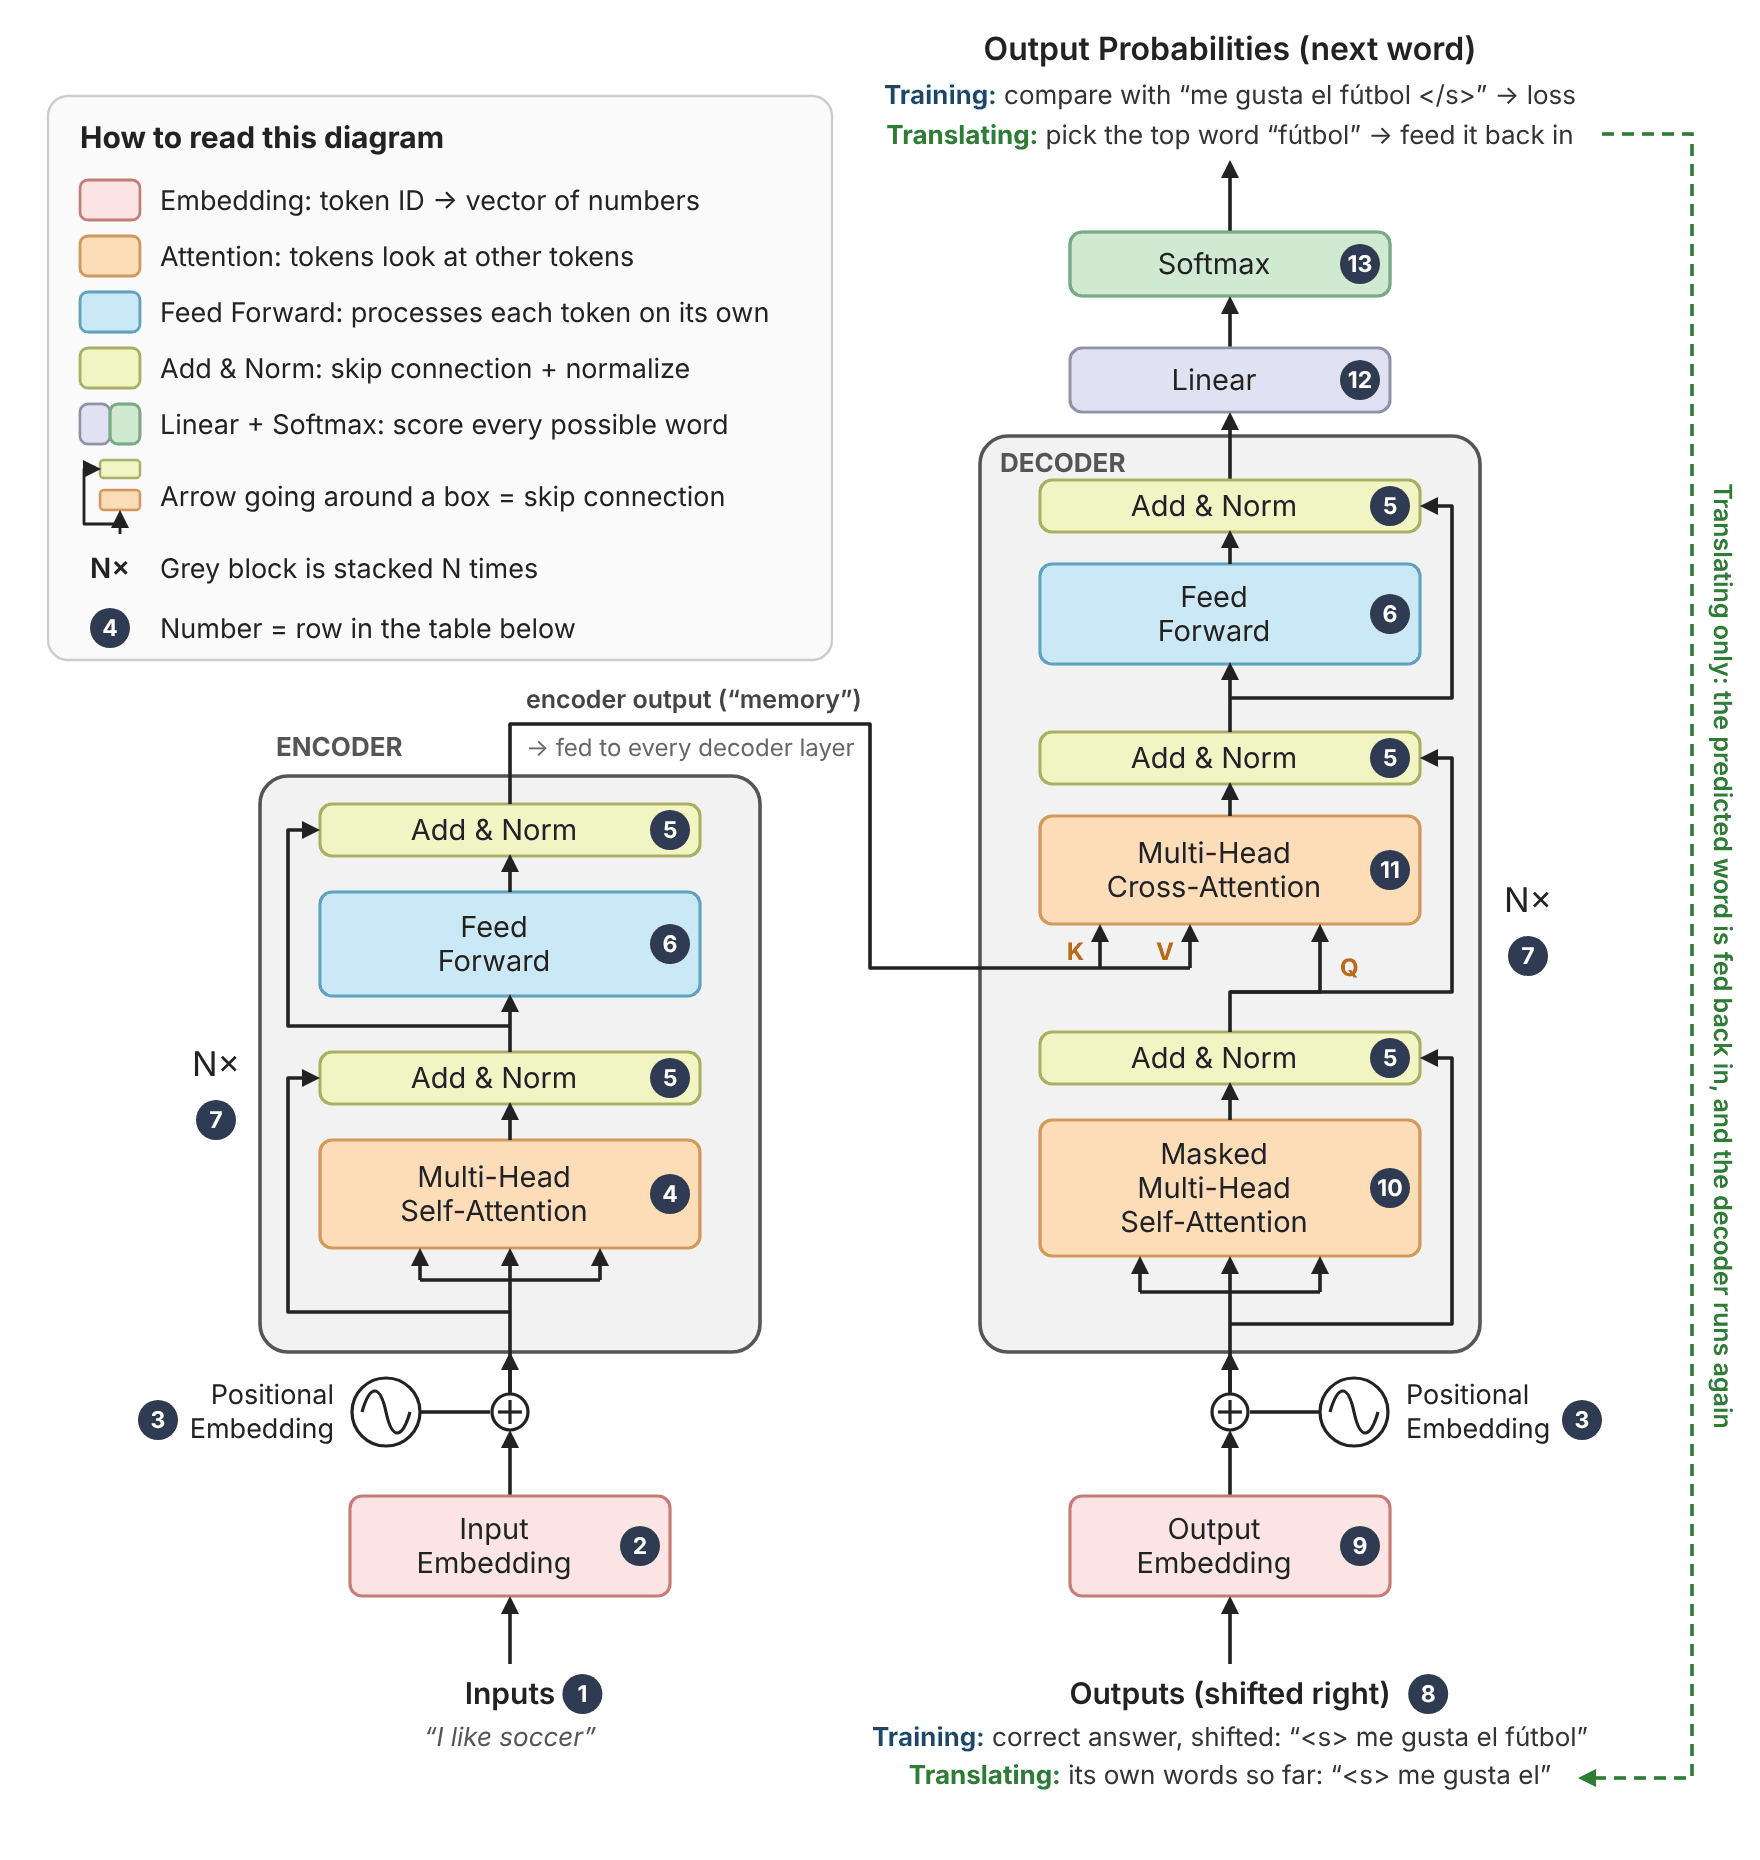

- **N** = number of stacked layers: **6 in the paper**, **2 in Géron's small model**.
- **Softmax [13]:** in PyTorch this is *not* a layer inside the model. The model outputs **logits**, and `nn.CrossEntropyLoss` applies the softmax internally. Call `F.softmax()` if you want the probabilities.

---

## Each element, step by step

**Shapes:** `B` = batch size, `L_src` / `L_tgt` = longest source / target sentence in the batch, `d` = embedding size (`d_model`: **512** in the paper, **128** in Géron's small model), `V` = vocabulary size.

| # | Element | What it does (plain English) | Output shape |
|---|---|---|---|
| **1** | **Inputs** | The source sentence as **token IDs** (integers). Shorter sentences are padded with `<pad>` so every sentence in the batch has the same length. | `[B, L_src]` |
| **2** | **Input Embedding** | `nn.Embedding` looks up a **vector of `d` numbers** for each token ID. At this point "like" still has its vague, out-of-context meaning. | `[B, L_src, d]` |
| **3** | **Positional Embedding** `(+)` | Attention is **position-agnostic**: without help, "dog bites man" and "man bites dog" look the same. So **position vector #i is added to token #i**. The paper used fixed sine/cosine waves. Géron uses **learned** position vectors (`nn.Parameter`) plus dropout, which works just as well. | same |
| **4** | **Multi-Head Self-Attention** (encoder) | Each token **looks at every token in the same sentence**, including itself, and pulls in what is relevant. This is where "like" notices the subject "I" and works out that it is a verb. "Multi-head" means this happens in **several heads in parallel** (8 in the paper, 4 in Géron), and each head can focus on a different feature (tense, meaning, …). | same |
| **5** | **Add & Norm** | **Add:** a skip connection adds the sub-layer's input back to its output. **Norm:** `LayerNorm` keeps the values in a stable range. Together they make deep stacks trainable. This wraps **every** sub-layer. In code: `norm1(src + dropout(attn))`. | same |
| **6** | **Feed Forward** | **Attention [4] = tokens talk to each other.** "like" collects clues from "I" and "soccer".<br><br>**Feed Forward = each token thinks alone.** "like" turns those clues into one clear meaning: *"enjoy (a sport)"*.<br><br>How: two `Linear` layers with a ReLU, `d → 2048 → d` (expand, filter, shrink back). It's applied to every token separately, with no looking at other tokens. | same |
| **7** | **N× stacking** | The layer (4 → 5 → 6 → 5) is repeated **N times**, and each layer refines the vectors further. The encoder's final output (PyTorch calls it the **memory**) is sent to **every** decoder layer. | `[B, L_src, d]` |
| **8** | **Outputs (shifted right)** | During training the target is `me gusta el fútbol </s>`, and the decoder is fed the same sentence **shifted right by one**: `<s> me gusta el fútbol`. Position *t* then has to predict token *t + 1*. This is called **teacher forcing**. | `[B, L_tgt]` |
| **9** | **Output Embedding + Positional** | Same as **2** and **3**, but for the target tokens. In Géron's code these are literally the **same layers**, because both languages share one vocabulary. | `[B, L_tgt, d]` |
| **10** | **Masked (causal) Self-Attention** (decoder) | Like **4**, but each token may only look at **itself and earlier tokens**. For example, "gusta" sees `<s>`, "me" and "gusta", but **not** "el" or "fútbol". Without the mask the model could copy the answer during training. | same |
| **11** | **Cross-Attention** (encoder → decoder) | The two halves **connect** here. **Queries (Q)** come from the decoder, and **keys (K) and values (V)** are the **encoder's final outputs**. When the decoder turns "el" into "fútbol", it pays close attention to **"soccer"**. | same |
| **12** | **Linear** | Maps each vector to **one score (logit) per vocabulary token**. Ideally the correct next token gets a high logit and every other token a low one. | `[B, L_tgt, V]` |
| **13** | **Softmax** | Turns the logits into **probabilities that sum to 1**, e.g. `P("fútbol") = 0.92`. In PyTorch it lives inside `nn.CrossEntropyLoss`. | `[B, L_tgt, V]` |

---

## How this connects to HW07

| Problem | Transformer concept involved |
|---|---|
| **1 – spaCy:** `prince − man + woman` | **Embeddings** (box **[2]**): meaning stored as vectors, so vector arithmetic and **cosine similarity** capture relationships between words. |
| **2 – French → English** | Géron's `NmtTransformer` with the languages swapped: **French** goes into **[1]** and **English** comes out of **[13]**. Hold out 10% of the pairs as the test set. |
| **3 – GPU memory** | Memory holds the **model weights**, the **Adam optimizer state** (two extra values per weight), **activations**, and the **attention grids**, which grow with *L²*. Géron's cleanup recipe: `del` the objects, then `gc.collect()`, then `torch.cuda.empty_cache()`. |
| **4 – BLEU score** | Scores a translation by how many **n-grams** (1–4 word chunks) it shares with a human reference translation. Higher is better. |

> **Coming up:** the next two cells walk through the whole translation and one training step. After that, *Going deeper* (optional) covers how attention computes its weights, the masks, and where each diagram box lives in Géron's code. Come back to that one when you start Problem 2.

# How "I like soccer" becomes "me gusta el fútbol" — the whole story in 4 steps

## Step 1 — Encoder: understand the English (runs **once**)

"I like soccer" → token IDs `[4, 5, 6]` → vectors → attention + feed-forward (× N)

**Result:** 3 vectors, one per English word, each now carrying context. These are the encoder's **notes** (`memory` in PyTorch):

| Word | What its note now says |
|---|---|
| I | the subject |
| like | verb: *"enjoy"* (not *"similar to"*) |
| soccer | a sport, the thing being liked |

## Step 2 — Decoder: write the Spanish, **one word per run**

On every run the decoder:
1. looks at **what it has written so far** (masked self-attention [10]),
2. checks the encoder's **notes** for what matters now (cross-attention [11]),
3. scores every Spanish word and **picks the most likely**,
4. **adds** that word, then runs again, until it outputs `</s>` (end).

| Run | Written so far | Mostly checks the note for… | Picks |
|---|---|---|---|
| 1 | `<s>` | "I", "like" | **me** |
| 2 | `<s> me` | "like" | **gusta** |
| 3 | `<s> me gusta` | "soccer" | **el** |
| 4 | `<s> me gusta el` | "soccer" | **fútbol** |
| 5 | `<s> me gusta el fútbol` | (nothing left) | **`</s>`** → stop |

*Note:* the decoder doesn't swap words one for one. Spanish says "I like" as **"me gusta"** ("it pleases me"), and the decoder learns that pattern.

## Step 3 — "Outputs (shifted right)": the decoder's input

The decoder's job at every slot is: **"given the words so far, guess the next word."** To set this up, the Spanish sentence is moved **one slot to the right**, and `<s>` fills the first slot:

| Slot | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| **Decoder input** (shifted right) | `<s>` | me | gusta | el | fútbol |
| **Must predict** | me | gusta | el | fútbol | `</s>` |

**Why shift?** Without it, slot 1 would show "me" *and* ask for "me", so the model would learn to **copy** instead of **predict**.

## Step 4 — How it learns this (training)

At first the weights are **random**, so every Spanish word gets about the same tiny probability. Training repeats a simple loop over thousands of sentence pairs:

| | What happens | Example (slot 1) |
|---|---|---|
| **Guess** | Decoder scores every Spanish word | P("me") = 0.0001 |
| **Check** | Loss compares the guess with the correct word | correct = "me" → big loss |
| **Adjust** | Backpropagation nudges **all** weights a little | P("me") goes up next time |

All 5 slots are trained **at once**: the whole shifted sentence goes in together, and the mask [10] stops each slot from peeking ahead. After many epochs, P("me") ≈ **0.95** whenever the notes say "I like…".

> **In one line:** the encoder turns the English into context-rich notes once; the decoder then writes Spanish one word at a time, each time asking "given what I've written and the notes, what comes next?", a skill learned by guessing, checking and adjusting over thousands of examples.

# Zoom in: one training step on "I like soccer"

**Setup:** the encoder has already made its 3 notes (**I**, **like**, **soccer**). The weights are still **random**. To keep it tiny, the Spanish vocabulary has only 5 words: `me`, `gusta`, `el`, `fútbol`, `</s>`.

## What the decoder gets, and what it must predict

During training we already know the answer, so the **whole correct sentence, shifted right**, goes in at once:

| Slot | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| **Input** | `<s>` | me | gusta | el | fútbol |
| **Must predict** | **me** | **gusta** | **el** | **fútbol** | **`</s>`** |

## Slot 1, step by step

| Step | What happens at slot 1 | Example (random weights) |
|---|---|---|
| **1. Embed** [9] | `<s>` becomes a vector | `[0.1, −0.2, 0.3]` |
| **2. Masked self-attention** [10] | Can only see itself, since the mask hides the later words | nothing new learned |
| **3. Cross-attention** [11] | Mixes in the encoder's notes | I 0.33 · like 0.33 · soccer 0.34 |
| **4. Feed forward** [6] | Processes that mix | — |
| **5. Linear + Softmax** [12–13] | Gives a probability for each Spanish word | see the next table |

**The guess at slot 1** (random weights, so it's wrong):

| Spanish word | me | gusta | el | fútbol | `</s>` |
|---|---|---|---|---|---|
| **Probability** | **0.19** ✗ | 0.23 | 0.14 | **0.28** ← guess | 0.17 |

**Then the model learns from the mistake:**

| Step | What happens |
|---|---|
| **6. Loss** | Correct answer is **"me"**, but P("me") = 0.19, so the loss = −log(0.19) ≈ **1.7** (high) |
| **7. Backprop** | Every weight is nudged a little to raise P("me"):<br><br>**Linear** scores "me" higher<br><br>**Cross-attention** looks more at "I" and "like"<br><br>**Encoder** makes those notes more useful |

## The other slots, at the same time

| Slot | Sees (thanks to the mask) | Target | Nudged towards… |
|---|---|---|---|
| 2 | `<s> me` | gusta | "like" note → "gusta" |
| 3 | `<s> me gusta` | el | "soccer" note → "el" |
| 4 | `<s> me gusta el` | fútbol | "soccer" note → "fútbol" |
| 5 | `<s> me gusta el fútbol` | `</s>` | sentence done → stop |

The 5 losses are **averaged**, and **one** backpropagation updates the weights for all of them.

## Repeat

| After… | P("me") at slot 1 |
|---|---|
| 1 step | 0.19 → 0.21 |
| 100 steps | 0.70 |
| many epochs | **0.95** |

> **Two things to remember**
> - With **one** sentence pair, the model would just **memorise** it. The general pattern "I like → me gusta" comes from **thousands** of different pairs, which is why Problem 2 trains on a whole dataset.
> - The model never stores a rule like "I = me". It learns: **"at slot 1, when the notes look like *I like…*, output *me*."**

## Does backpropagation only update the decoder? No, it updates the whole model

The loss is measured only at the decoder's output, but the error flows **backwards along every path that helped make the guess**:

**Loss → Linear [12] → decoder layers → cross-attention [11] → encoder's notes → encoder layers → embeddings [2]/[9] + positions [3]**

| Part | Learns to… |
|---|---|
| Linear [12] | score the right word higher |
| Decoder layers | use the words so far and the notes better |
| Encoder layers | write more useful notes ("like" → clearly "enjoy") |
| Embeddings + positions | give each token a better starting vector |

> **Key idea:** the encoder has **no loss of its own**. It learns **only** through cross-attention [11], from the decoder's mistakes. Both halves are trained **together** in one step: `loss.backward()` then `optimizer.step()`.

# Part 0b — Going deeper (optional)

*Read this when you start **Problem 2**. It refers to the numbered boxes `[1]`–`[13]` in the diagram above.*

---

## Training vs. translating (inference)

| | Training | Translating (inference) |
|---|---|---|
| Decoder input | The full correct target, shifted right: `<s> me gusta el fútbol` | Starts with only `<s>` |
| How it runs | All positions are predicted **at once, in parallel**. The causal mask **[10]** stops cheating. | **One token per call:** predict, append, call again, until `</s>` (the 5-call table above) |
| Loss | `nn.CrossEntropyLoss` against `me gusta el fútbol </s>` | none |

---

## Zoom in: how attention works

$$
\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V
$$

Think of a **library search**:

- **Q (Query):** *"what am I looking for?"*, asked by the token being updated.
- **K (Key):** *"what do I contain?"*, a label on every token.
- **V (Value):** *"here is my actual information"*.

It works in five steps:

1. **Score:** `QKᵀ` gives a similarity score for **every query/key pair**, an `[L_q, L_k]` grid. The grid grows with the **square** of the sentence length, which is why long inputs are expensive (relevant to **Problem 3**).
2. **Scale:** divide by `√d_k` so the softmax doesn't saturate. A saturated softmax gives tiny gradients and slow training.
3. **Mask:** set every forbidden score to `−∞`, so its weight becomes exactly 0. This is how padding and future tokens are hidden.
4. **Softmax** each row, so each token's weights add up to 1.
5. **Mix:** the output for each token is the **weighted sum of the values**.

**Toy example (illustrative numbers):** updating the token **"like"** in "I like soccer":

| Looks at → | `I` | `like` | `soccer` |
|---|---|---|---|
| attention weight | **0.50** | 0.30 | 0.20 |

New "like" = 0.50·V(`I`) + 0.30·V(`like`) + 0.20·V(`soccer`). It now "knows" it has the subject "I", so it is a verb.

**The two masks.** A **padding mask** ignores `<pad>` tokens (`*_key_padding_mask`). A **causal mask** hides future tokens in the decoder (`tgt_mask`). For decoder input `<s> me gusta el`, the causal mask looks like this (✓ = may look at):

| token ↓ looks at → | `<s>` | `me` | `gusta` | `el` |
|---|---|---|---|---|
| `<s>` | ✓ | | | |
| `me` | ✓ | ✓ | | |
| `gusta` | ✓ | ✓ | ✓ | |
| `el` | ✓ | ✓ | ✓ | ✓ |

Géron builds it with `torch.triu(full_mask, diagonal=1)`, which is `True` above the diagonal, meaning "hide".

**Multi-head attention** runs several small attentions side by side, so each head can focus on a different feature:

```text
                         ┌─► head 1: attention ─┐
token vectors ─► Linear ─┼─► head 2: attention ─┼─► concatenate ─► Linear ─► output
  (Q, K, V)    (per head)└─► … head h …        ─┘
```

---

## The diagram ↔ Géron's PyTorch code (`NmtTransformer`)

| Diagram box | Where it lives in the code |
|---|---|
| **[2]**, **[9]** embeddings | `self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)`, shared by source and target |
| **[3]** positional | `PositionalEmbedding`: `X + self.pos_embed[:X.size(1)]`, then dropout |
| **[4]–[11]** encoder + decoder stacks | `nn.Transformer(embed_dim, num_heads, num_encoder_layers=N, num_decoder_layers=N, batch_first=True)` |
| **[5]** Add & Norm | `Z = self.norm1(src + self.dropout(attn))` |
| **[6]** Feed Forward | `self.linear2(self.dropout(self.linear1(Z).relu()))` |
| **[10]** causal mask | `causal_mask = torch.triu(full_mask, diagonal=1)` → `tgt_mask=causal_mask, tgt_is_causal=True` |
| padding masks | `src_key_padding_mask`, `memory_key_padding_mask`, `tgt_key_padding_mask` |
| **[11]** cross-attention | `self.multihead_attn(Z, memory, memory)`: Q = decoder `Z`, K = V = encoder `memory` |
| **[12]** Linear | `self.output = nn.Linear(embed_dim, vocab_size)` |
| **[13]** Softmax | inside `nn.CrossEntropyLoss` |
| **Size** | paper: `embed_dim=512, num_heads=8, num_layers=6`; Géron's small model: `128, 4, 2` |